In [2]:
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)

Current working directory:
C:\Users\Santosh Dani\ project panopticon

Files and folders here:
.ipynb_checkpoints
datasets
project panopticon.ipynb


In [5]:
from pathlib import Path

for file in Path.cwd().rglob("*.csv"):
    print(file)

C:\Users\Santosh Dani\ project panopticon\datasets\system_events .csv
C:\Users\Santosh Dani\ project panopticon\datasets\video_telemetry.csv
C:\Users\Santosh Dani\ project panopticon\datasets\.ipynb_checkpoints\system_events -checkpoint.csv
C:\Users\Santosh Dani\ project panopticon\datasets\.ipynb_checkpoints\video_telemetry-checkpoint.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset folder
DATA_DIR = Path("datasets")

# Load both datasets using their exact filenames
video = pd.read_csv(DATA_DIR / "video_telemetry.csv")
events = pd.read_csv(DATA_DIR / "system_events .csv")

print("Datasets loaded successfully!!!")

print("Video dataset shape:", video.shape)
print("Events dataset shape:", events.shape)

Datasets loaded successfully!!!
Video dataset shape: (10000, 3)
Events dataset shape: (167, 3)


In [8]:
print("VIDEO TELEMETRY")
print("Columns:", video.columns.tolist())
display(video.head())
print("\nMissing values:")
print(video.isnull().sum())

print("\n" + "=" * 50)

print("SYSTEM EVENTS")
print("Columns:", events.columns.tolist())
display(events.head())
print("\nMissing values:")
print(events.isnull().sum())

VIDEO TELEMETRY
Columns: ['timestamp', 'eye_gaze_angle', 'audio_db']


,timestamp,eye_gaze_angle,audio_db
0,2023-12-01 08:00:00,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627
2,2023-12-01 08:00:02,5.761714,31.228565
3,2023-12-01 08:00:03,9.787105,34.051405
4,2023-12-01 08:00:04,4.572665,35.245018



Missing values:
timestamp           0
eye_gaze_angle    732
audio_db          732
dtype: int64

SYSTEM EVENTS
Columns: ['timestamp', 'tab_switches', 'is_cheating']


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0



Missing values:
timestamp       0
tab_switches    0
is_cheating     0
dtype: int64


In [9]:
# Convert timestamp columns to datetime
video["timestamp"] = pd.to_datetime(video["timestamp"])
events["timestamp"] = pd.to_datetime(events["timestamp"])

print("Video timestamp type:", video["timestamp"].dtype)
print("Events timestamp type:", events["timestamp"].dtype)

Video timestamp type: datetime64[ns]
Events timestamp type: datetime64[ns]


In [10]:
#sorting both datasets by time
video = video.sort_values("timestamp").reset_index(drop=True)
events = events.sort_values("timestamp").reset_index(drop=True)

print("Video timestamps sorted:", video["timestamp"].is_monotonic_increasing)
print("Event timestamps sorted:", events["timestamp"].is_monotonic_increasing)

Video timestamps sorted: True
Event timestamps sorted: True


In [12]:
#check missing value pattern
print("Missing values before cleaning:")
print(video[["eye_gaze_angle", "audio_db"]].isnull().sum())

print("\nTotal video rows:", len(video))
#interpolation 
sensor_columns = ["eye_gaze_angle", "audio_db"]

video[sensor_columns] = (
    video[sensor_columns]
    .interpolate(method="linear", limit_area="inside")
)

print("Missing values after interpolation:")
print(video[sensor_columns].isnull().sum())
#remaining values
print("Remaining missing values:")
print(video.isnull().sum())

print("\nDataset shape:", video.shape)

Missing values before cleaning:
eye_gaze_angle    0
audio_db          0
dtype: int64

Total video rows: 10000
Missing values after interpolation:
eye_gaze_angle    0
audio_db          0
dtype: int64
Remaining missing values:
timestamp         0
eye_gaze_angle    0
audio_db          0
dtype: int64

Dataset shape: (10000, 3)


In [13]:
#align both datasets
print("Video time range:")
print(video["timestamp"].min(), "to", video["timestamp"].max())

print("\nEvents time range:")
print(events["timestamp"].min(), "to", events["timestamp"].max())

print("\nNumber of event rows:", len(events))

print("\nCheating label distribution:")
print(events["is_cheating"].value_counts())

Video time range:
2023-12-01 08:00:00 to 2023-12-01 10:46:39

Events time range:
2023-12-01 08:00:32.181296 to 2023-12-01 10:45:39.962066

Number of event rows: 167

Cheating label distribution:
is_cheating
0    90
1    77
Name: count, dtype: int64


In [14]:
# Sort both datasets by timestamp
video = video.sort_values("timestamp").reset_index(drop=True)
events = events.sort_values("timestamp").reset_index(drop=True)

# Align each video timestamp with the nearest system event
merged = pd.merge_asof(
    video,
    events,
    on="timestamp",
    direction="nearest",
    tolerance=pd.Timedelta("1s")
)

print("Merged dataset shape:", merged.shape)

print("\nFirst 10 rows:")
display(merged.head(10))

print("\nMissing values after merge:")
print(merged.isnull().sum())

Merged dataset shape: (10000, 5)

First 10 rows:


,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating
0,2023-12-01 08:00:00,2.560857,36.553781,NaN,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,NaN,NaN
2,2023-12-01 08:00:02,5.761714,31.228565,NaN,NaN
3,2023-12-01 08:00:03,9.787105,34.051405,NaN,NaN
4,2023-12-01 08:00:04,4.572665,35.245018,NaN,NaN
5,2023-12-01 08:00:05,7.471741,43.685711,NaN,NaN
6,2023-12-01 08:00:06,7.148505,32.754163,NaN,NaN
7,2023-12-01 08:00:07,9.192380,43.786308,NaN,NaN
8,2023-12-01 08:00:08,4.223888,34.097144,NaN,NaN
9,2023-12-01 08:00:09,3.524030,39.177137,NaN,NaN



Missing values after merge:
timestamp            0
eye_gaze_angle       0
audio_db             0
tab_switches      9675
is_cheating       9675
dtype: int64


In [15]:
print("Event label counts:")
print(events["is_cheating"].value_counts(dropna=False))

print("\nEvent label proportions:")
print(events["is_cheating"].value_counts(normalize=True))

print("\nFirst 15 events:")
display(events[["timestamp", "tab_switches", "is_cheating"]].head(15))

Event label counts:
is_cheating
0    90
1    77
Name: count, dtype: int64

Event label proportions:
is_cheating
0    0.538922
1    0.461078
Name: proportion, dtype: float64

First 15 events:


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0
5,2023-12-01 08:05:06.991353,1,0
6,2023-12-01 08:05:45.348918,1,0
7,2023-12-01 08:10:27.705789,1,0
8,2023-12-01 08:10:28.634146,1,1
9,2023-12-01 08:11:45.471622,1,0


In [16]:
events = events.sort_values("timestamp").copy()

events["gap_seconds"] = (
    events["timestamp"].diff().dt.total_seconds()
)

print(events["gap_seconds"].describe())

print("\nLargest event gaps:")
display(
    events.nlargest(10, "gap_seconds")[
        ["timestamp", "gap_seconds", "is_cheating"]
    ]
)

count    166.000000
mean      59.685426
std       75.855487
min        0.394166
25%       10.638091
50%       29.561680
75%       74.199844
max      422.081798
Name: gap_seconds, dtype: float64

Largest event gaps:


,timestamp,gap_seconds,is_cheating
71,2023-12-01 09:11:18.563371,422.081798,0
132,2023-12-01 10:15:57.062334,313.916443,0
97,2023-12-01 09:38:56.367400,283.684092,0
7,2023-12-01 08:10:27.705789,282.356871,0
137,2023-12-01 10:24:04.776714,281.020045,0
165,2023-12-01 10:45:03.671797,264.507728,1
94,2023-12-01 09:33:54.216082,250.321339,1
30,2023-12-01 08:30:20.764547,245.760697,0
119,2023-12-01 09:59:09.395564,230.534887,0
44,2023-12-01 08:45:07.635464,225.337137,0


In [17]:
import pandas as pd
import numpy as np

# Make sure timestamps are datetime objects
video["timestamp"] = pd.to_datetime(video["timestamp"])
events["timestamp"] = pd.to_datetime(events["timestamp"])

# Sort by timestamp
video = video.sort_values("timestamp").reset_index(drop=True)
events = events.sort_values("timestamp").reset_index(drop=True)

# Feature 1: Time gap between consecutive events
events["gap_seconds"] = (
    events["timestamp"].diff().dt.total_seconds()
)

# Feature 2: Number of tab switches in a rolling window
events["tab_switches_5"] = (
    events["tab_switches"].rolling(5, min_periods=1).sum()
)

# Feature 3: Rolling average of eye gaze
video["gaze_mean_5"] = (
    video["eye_gaze_angle"].rolling(5, min_periods=1).mean()
)

# Feature 4: Rolling average of audio level
video["audio_mean_5"] = (
    video["audio_db"].rolling(5, min_periods=1).mean()
)

print("Event features:")
display(events.head())

print("Video features:")
display(video.head())

Event features:


,timestamp,tab_switches,is_cheating,gap_seconds,tab_switches_5
0,2023-12-01 08:00:32.181296,1,0,NaN,1.0
1,2023-12-01 08:01:01.923778,1,1,29.742482,2.0
2,2023-12-01 08:01:24.462808,1,0,22.539030,3.0
3,2023-12-01 08:04:10.610743,1,0,166.147935,4.0
4,2023-12-01 08:04:23.902814,1,0,13.292071,5.0


Video features:


,timestamp,eye_gaze_angle,audio_db,gaze_mean_5,audio_mean_5
0,2023-12-01 08:00:00,2.560857,36.553781,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627,6.368997,37.828204
2,2023-12-01 08:00:02,5.761714,31.228565,6.166569,35.628325
3,2023-12-01 08:00:03,9.787105,34.051405,7.071703,35.234095
4,2023-12-01 08:00:04,4.572665,35.245018,6.571896,35.236279


In [18]:
# Keep only the columns needed for merging
video_features = video[
    [
        "timestamp",
        "eye_gaze_angle",
        "audio_db",
        "gaze_mean_5",
        "audio_mean_5"
    ]
].copy()

events_features = events[
    [
        "timestamp",
        "tab_switches",
        "is_cheating",
        "gap_seconds",
        "tab_switches_5"
    ]
].copy()

# Sort both datasets by timestamp
video_features = video_features.sort_values("timestamp")
events_features = events_features.sort_values("timestamp")

# Match each video reading with the most recent event
merged = pd.merge_asof(
    video_features,
    events_features,
    on="timestamp",
    direction="backward"
)

print("Merged dataset shape:", merged.shape)
print("\nMissing values after alignment:")
print(merged.isnull().sum())

display(merged.head(10))

Merged dataset shape: (10000, 9)

Missing values after alignment:
timestamp          0
eye_gaze_angle     0
audio_db           0
gaze_mean_5        0
audio_mean_5       0
tab_switches      33
is_cheating       33
gap_seconds       62
tab_switches_5    33
dtype: int64


,timestamp,eye_gaze_angle,audio_db,gaze_mean_5,audio_mean_5,tab_switches,is_cheating,gap_seconds,tab_switches_5
0,2023-12-01 08:00:00,2.560857,36.553781,2.560857,36.553781,NaN,NaN,NaN,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,6.368997,37.828204,NaN,NaN,NaN,NaN
2,2023-12-01 08:00:02,5.761714,31.228565,6.166569,35.628325,NaN,NaN,NaN,NaN
3,2023-12-01 08:00:03,9.787105,34.051405,7.071703,35.234095,NaN,NaN,NaN,NaN
4,2023-12-01 08:00:04,4.572665,35.245018,6.571896,35.236279,NaN,NaN,NaN,NaN
5,2023-12-01 08:00:05,7.471741,43.685711,7.554073,36.662665,NaN,NaN,NaN,NaN
6,2023-12-01 08:00:06,7.148505,32.754163,6.948346,35.392973,NaN,NaN,NaN,NaN
7,2023-12-01 08:00:07,9.192380,43.786308,7.634479,37.904521,NaN,NaN,NaN,NaN
8,2023-12-01 08:00:08,4.223888,34.097144,6.521836,37.913669,NaN,NaN,NaN,NaN
9,2023-12-01 08:00:09,3.524030,39.177137,6.312109,38.700093,NaN,NaN,NaN,NaN


In [19]:
# Check rows where no system event has been matched
print("Rows without a matched event:")
print(merged["is_cheating"].isnull().sum())

# Check the timestamps of the unmatched rows
display(
    merged[merged["is_cheating"].isnull()][["timestamp"]].head(10)
)

# Remove rows without a valid cheating label
# Do not assume missing labels mean 0
model_data = merged.dropna(subset=["is_cheating"]).copy()

# The first event has no previous event, so its gap is undefined.
# Keep other missing gaps for now and inspect them.
print("\nDataset shape after removing unlabeled rows:", model_data.shape)
print("\nRemaining missing values:")
print(model_data.isnull().sum())

Rows without a matched event:
33


,timestamp
0,2023-12-01 08:00:00
1,2023-12-01 08:00:01
2,2023-12-01 08:00:02
3,2023-12-01 08:00:03
4,2023-12-01 08:00:04
5,2023-12-01 08:00:05
6,2023-12-01 08:00:06
7,2023-12-01 08:00:07
8,2023-12-01 08:00:08
9,2023-12-01 08:00:09



Dataset shape after removing unlabeled rows: (9967, 9)

Remaining missing values:
timestamp          0
eye_gaze_angle     0
audio_db           0
gaze_mean_5        0
audio_mean_5       0
tab_switches       0
is_cheating        0
gap_seconds       29
tab_switches_5     0
dtype: int64


In [20]:
#ML dataset
# Fill missing time gaps with 0 for now
model_data["gap_seconds"] = (
    model_data["gap_seconds"].fillna(0)
)

# Select input features
feature_columns = [
    "eye_gaze_angle",
    "audio_db",
    "gaze_mean_5",
    "audio_mean_5",
    "tab_switches",
    "gap_seconds",
    "tab_switches_5"
]

X = model_data[feature_columns].copy()
y = model_data["is_cheating"].astype(int).copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

display(X.head())

Feature dataset shape: (9967, 7)
Target dataset shape: (9967,)

Target distribution:
is_cheating
0    6773
1    3194
Name: count, dtype: int64

Target proportions:
is_cheating
0    0.679542
1    0.320458
Name: proportion, dtype: float64


,eye_gaze_angle,audio_db,gaze_mean_5,audio_mean_5,tab_switches,gap_seconds,tab_switches_5
33,5.671498,29.353502,4.864430,33.229939,1.0,0.0,1.0
34,5.317689,32.185477,4.280929,33.114801,1.0,0.0,1.0
35,6.992439,28.427369,4.390128,32.961162,1.0,0.0,1.0
36,6.195533,33.713829,5.155590,32.305085,1.0,0.0,1.0
37,10.538424,38.218019,6.943117,32.379639,1.0,0.0,1.0


In [22]:
#split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (7973, 7)
Testing features: (1994, 7)
Training target: (7973,)
Testing target: (1994,)


In [27]:
#random forest algorithm
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [28]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9924774322968907

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1355
           1       0.99      0.98      0.99       639

    accuracy                           0.99      1994
   macro avg       0.99      0.99      0.99      1994
weighted avg       0.99      0.99      0.99      1994


Confusion Matrix:
[[1350    5]
 [  10  629]]


Feature Importance:
gap_seconds       0.451273
tab_switches      0.232747
tab_switches_5    0.159639
gaze_mean_5       0.057071
audio_mean_5      0.045204
audio_db          0.027098
eye_gaze_angle    0.026967
dtype: float64


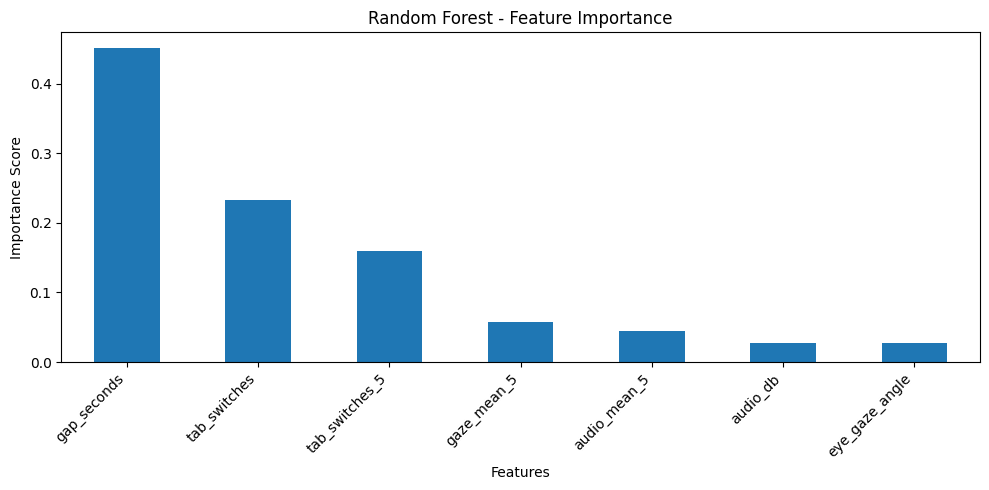

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("Random Forest - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [30]:
print("Feature columns:")
print(X.columns.tolist())

print("\nTarget column:")
print(y.name)

print("\nFeature correlations with target:")
print(
    pd.concat([X, y.rename("target")], axis=1)
      .corr(numeric_only=True)["target"]
      .drop("target")
      .sort_values(ascending=False)
)

Feature columns:
['eye_gaze_angle', 'audio_db', 'gaze_mean_5', 'audio_mean_5', 'tab_switches', 'gap_seconds', 'tab_switches_5']

Target column:
is_cheating

Feature correlations with target:
tab_switches      0.637389
tab_switches_5    0.449905
gaze_mean_5       0.275517
audio_mean_5      0.257194
eye_gaze_angle    0.218502
audio_db          0.191992
gap_seconds      -0.180030
Name: target, dtype: float64


In [31]:
# Check whether the target is constant for each tab-switch value
print("Cheating rate by tab_switches:")
display(
    model_data.groupby("tab_switches")["is_cheating"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
    .head(15)
)

# Compare target labels before and after alignment
print("\nOriginal event label distribution:")
print(events["is_cheating"].value_counts(normalize=True))

print("\nMerged label distribution:")
print(merged["is_cheating"].value_counts(normalize=True))

# Check how many video rows are associated with each event label
print("\nRows per label after merging:")
print(merged["is_cheating"].value_counts(dropna=False))

Cheating rate by tab_switches:


,count,mean
tab_switches,,
2.0,1016,1.000000
3.0,778,1.000000
1.0,8173,0.171296



Original event label distribution:
is_cheating
0    0.538922
1    0.461078
Name: proportion, dtype: float64

Merged label distribution:
is_cheating
0.0    0.679542
1.0    0.320458
Name: proportion, dtype: float64

Rows per label after merging:
is_cheating
0.0    6773
1.0    3194
NaN      33
Name: count, dtype: int64


In [32]:
# Inspect how long each event label is being carried forward
events_check = events.sort_values("timestamp").copy()
video_check = video.sort_values("timestamp").copy()

merged_check = pd.merge_asof(
    video_check,
    events_check[["timestamp", "is_cheating", "tab_switches"]],
    on="timestamp",
    direction="backward"
)

print("Video rows:", len(video_check))
print("Rows with no matching earlier event:",
      merged_check["is_cheating"].isna().sum())

print("\nLabel distribution after merging:")
print(merged_check["is_cheating"].value_counts())

print("\nOriginal event labels:")
print(events["is_cheating"].value_counts())

Video rows: 10000
Rows with no matching earlier event: 33

Label distribution after merging:
is_cheating
0.0    6773
1.0    3194
Name: count, dtype: int64

Original event labels:
is_cheating
0    90
1    77
Name: count, dtype: int64


In [33]:
# Check the time span and intervals between events
events_sorted = events.sort_values("timestamp").copy()

events_sorted["interval_seconds"] = (
    events_sorted["timestamp"].diff().dt.total_seconds()
)

print("First video timestamp:", video["timestamp"].min())
print("Last video timestamp:", video["timestamp"].max())

print("\nFirst event timestamp:", events_sorted["timestamp"].min())
print("Last event timestamp:", events_sorted["timestamp"].max())

print("\nEvent intervals (seconds):")
display(events_sorted["interval_seconds"].describe())

print("\nLongest 10 event intervals:")
display(
    events_sorted.nlargest(10, "interval_seconds")[
        ["timestamp", "interval_seconds", "is_cheating"]
    ]
)

First video timestamp: 2023-12-01 08:00:00
Last video timestamp: 2023-12-01 10:46:39

First event timestamp: 2023-12-01 08:00:32.181296
Last event timestamp: 2023-12-01 10:45:39.962066

Event intervals (seconds):


count    166.000000
mean      59.685426
std       75.855487
min        0.394166
25%       10.638091
50%       29.561680
75%       74.199844
max      422.081798
Name: interval_seconds, dtype: float64


Longest 10 event intervals:


,timestamp,interval_seconds,is_cheating
71,2023-12-01 09:11:18.563371,422.081798,0
132,2023-12-01 10:15:57.062334,313.916443,0
97,2023-12-01 09:38:56.367400,283.684092,0
7,2023-12-01 08:10:27.705789,282.356871,0
137,2023-12-01 10:24:04.776714,281.020045,0
165,2023-12-01 10:45:03.671797,264.507728,1
94,2023-12-01 09:33:54.216082,250.321339,1
30,2023-12-01 08:30:20.764547,245.760697,0
119,2023-12-01 09:59:09.395564,230.534887,0
44,2023-12-01 08:45:07.635464,225.337137,0


In [36]:
print("Event dataset columns:")
print(events.columns.tolist())

print("\nFirst 10 events:")
display(events.sort_values("timestamp").head(10))

print("\nLast 10 events:")
display(events.sort_values("timestamp").tail(10))

print("\nVideo timestamp frequency:")
print(
    video.sort_values("timestamp")["timestamp"]
    .diff()
    .dt.total_seconds()
    .describe()
    .round(3)
)

Event dataset columns:
['timestamp', 'tab_switches', 'is_cheating', 'gap_seconds', 'tab_switches_5']

First 10 events:


,timestamp,tab_switches,is_cheating,gap_seconds,tab_switches_5
0,2023-12-01 08:00:32.181296,1,0,NaN,1.0
1,2023-12-01 08:01:01.923778,1,1,29.742482,2.0
2,2023-12-01 08:01:24.462808,1,0,22.539030,3.0
3,2023-12-01 08:04:10.610743,1,0,166.147935,4.0
4,2023-12-01 08:04:23.902814,1,0,13.292071,5.0
5,2023-12-01 08:05:06.991353,1,0,43.088539,5.0
6,2023-12-01 08:05:45.348918,1,0,38.357565,5.0
7,2023-12-01 08:10:27.705789,1,0,282.356871,5.0
8,2023-12-01 08:10:28.634146,1,1,0.928357,5.0
9,2023-12-01 08:11:45.471622,1,0,76.837476,5.0



Last 10 events:


,timestamp,tab_switches,is_cheating,gap_seconds,tab_switches_5
157,2023-12-01 10:34:33.181174,3,1,15.367219,11.0
158,2023-12-01 10:34:41.804595,3,1,8.623421,13.0
159,2023-12-01 10:35:28.544525,1,0,46.739930,11.0
160,2023-12-01 10:38:50.562447,1,1,202.017922,11.0
161,2023-12-01 10:38:54.020092,3,1,3.457645,11.0
162,2023-12-01 10:38:55.980618,3,1,1.960526,11.0
163,2023-12-01 10:39:01.943939,1,1,5.963321,9.0
164,2023-12-01 10:40:39.164069,3,1,97.220130,11.0
165,2023-12-01 10:45:03.671797,3,1,264.507728,13.0
166,2023-12-01 10:45:39.962066,1,0,36.290269,11.0



Video timestamp frequency:
count    9999.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: timestamp, dtype: float64


In [37]:
# 1. Inspect the original event records
print("EVENT DATASET")
print("Shape:", events.shape)
print("Columns:", events.columns.tolist())
print(events.sort_values("timestamp").head(10).to_string(index=False))

# 2. Inspect the video sampling frequency
print("\nVIDEO DATASET")
print("Shape:", video.shape)
print("Columns:", video.columns.tolist())

video_intervals = (
    video.sort_values("timestamp")["timestamp"]
    .diff()
    .dt.total_seconds()
)

print("\nVideo intervals in seconds:")
print(video_intervals.describe().round(3))

# 3. Check the original label values
print("\nOriginal labels:")
print(events["is_cheating"].value_counts(dropna=False))

EVENT DATASET
Shape: (167, 5)
Columns: ['timestamp', 'tab_switches', 'is_cheating', 'gap_seconds', 'tab_switches_5']
                 timestamp  tab_switches  is_cheating  gap_seconds  tab_switches_5
2023-12-01 08:00:32.181296             1            0          NaN             1.0
2023-12-01 08:01:01.923778             1            1    29.742482             2.0
2023-12-01 08:01:24.462808             1            0    22.539030             3.0
2023-12-01 08:04:10.610743             1            0   166.147935             4.0
2023-12-01 08:04:23.902814             1            0    13.292071             5.0
2023-12-01 08:05:06.991353             1            0    43.088539             5.0
2023-12-01 08:05:45.348918             1            0    38.357565             5.0
2023-12-01 08:10:27.705789             1            0   282.356871             5.0
2023-12-01 08:10:28.634146             1            1     0.928357             5.0
2023-12-01 08:11:45.471622             1            0

In [38]:
import pandas as pd

# Make independent, timestamp-sorted copies
video_sorted = video.sort_values("timestamp").copy()
events_sorted = events.sort_values("timestamp").copy()

# Keep only the video features needed for modeling
video_features = video_sorted[
    [
        "timestamp",
        "eye_gaze_angle",
        "audio_db",
        "gaze_mean_5",
        "audio_mean_5",
    ]
].copy()

# Attach the latest available video observation to each event
event_data = pd.merge_asof(
    events_sorted,
    video_features,
    on="timestamp",
    direction="backward",
    tolerance=pd.Timedelta(seconds=2),
)

print("Event-level dataset shape:", event_data.shape)
print("\nMissing values:")
print(event_data.isna().sum())

print("\nFirst 10 rows:")
print(event_data.head(10).to_string(index=False))

print("\nLabel distribution:")
print(event_data["is_cheating"].value_counts())

Event-level dataset shape: (167, 9)

Missing values:
timestamp         0
tab_switches      0
is_cheating       0
gap_seconds       1
tab_switches_5    0
eye_gaze_angle    0
audio_db          0
gaze_mean_5       0
audio_mean_5      0
dtype: int64

First 10 rows:
                 timestamp  tab_switches  is_cheating  gap_seconds  tab_switches_5  eye_gaze_angle  audio_db  gaze_mean_5  audio_mean_5
2023-12-01 08:00:32.181296             1            0          NaN             1.0        1.600790 37.845251     4.937458     34.603413
2023-12-01 08:01:01.923778             1            1    29.742482             2.0       39.928129 58.863681    46.385396     64.536556
2023-12-01 08:01:24.462808             1            0    22.539030             3.0        5.795597 31.423961     5.267812     35.262323
2023-12-01 08:04:10.610743             1            0   166.147935             4.0       22.350972 51.842922    14.980210     45.539655
2023-12-01 08:04:23.902814             1            0    1

In [39]:
# Create a clean event-level modeling dataset
model_events = event_data.dropna(
    subset=["eye_gaze_angle", "audio_db", "gaze_mean_5", "audio_mean_5"]
).copy()

# Exclude the first event because its gap_seconds is undefined
model_events = model_events.dropna(subset=["gap_seconds"]).copy()

# Define features and target
feature_columns = [
    "eye_gaze_angle",
    "audio_db",
    "gaze_mean_5",
    "audio_mean_5",
    "tab_switches",
    "tab_switches_5",
]

X_event = model_events[feature_columns]
y_event = model_events["is_cheating"].astype(int)

print("Model dataset shape:", X_event.shape)
print("\nLabel distribution:")
print(y_event.value_counts())

print("\nMissing feature values:")
print(X_event.isna().sum())

Model dataset shape: (166, 6)

Label distribution:
is_cheating
0    89
1    77
Name: count, dtype: int64

Missing feature values:
eye_gaze_angle    0
audio_db          0
gaze_mean_5       0
audio_mean_5      0
tab_switches      0
tab_switches_5    0
dtype: int64


In [40]:
#split the data and train the random forest 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
import pandas as pd

# Ensure events are in chronological order
model_events = model_events.sort_values("timestamp").reset_index(drop=True)

feature_columns = [
    "eye_gaze_angle",
    "audio_db",
    "gaze_mean_5",
    "audio_mean_5",
    "tab_switches",
    "tab_switches_5",
]

X_event = model_events[feature_columns]
y_event = model_events["is_cheating"].astype(int)

# Use the first 80% for training and the last 20% for testing
split_index = int(len(model_events) * 0.8)

X_train = X_event.iloc[:split_index]
X_test = X_event.iloc[split_index:]
y_train = y_event.iloc[:split_index]
y_test = y_event.iloc[split_index:]

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Training period:",
      model_events["timestamp"].iloc[0],
      "to",
      model_events["timestamp"].iloc[split_index - 1])
print("Testing period:",
      model_events["timestamp"].iloc[split_index],
      "to",
      model_events["timestamp"].iloc[-1])

# Train the baseline model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# Evaluate on later events
y_pred = model.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Not cheating", "Cheating"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Training examples: 132
Testing examples: 34
Training period: 2023-12-01 08:01:01.923778 to 2023-12-01 10:15:57.062334
Testing period: 2023-12-01 10:17:29.778337 to 2023-12-01 10:45:39.962066

Accuracy: 0.9412

Classification report:
              precision    recall  f1-score   support

Not cheating       1.00      0.88      0.93        16
    Cheating       0.90      1.00      0.95        18

    accuracy                           0.94        34
   macro avg       0.95      0.94      0.94        34
weighted avg       0.95      0.94      0.94        34

Confusion matrix:
[[14  2]
 [ 0 18]]


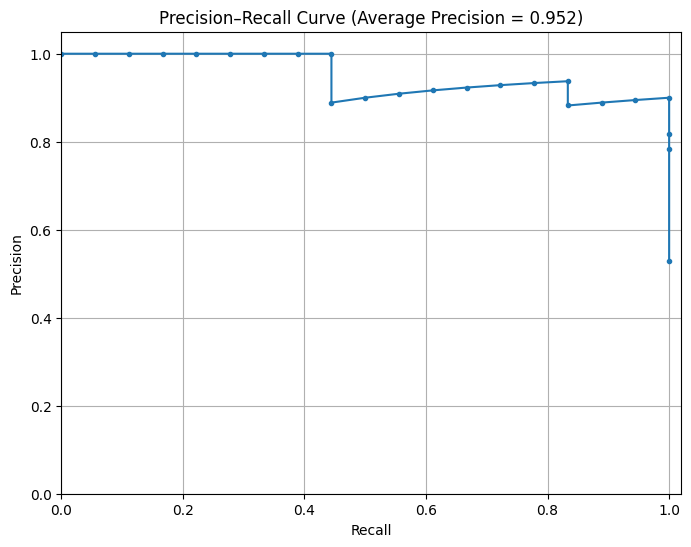

Average precision: 0.9518
Number of thresholds: 23


In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
)

# Probability that each test event belongs to class 1
y_scores = model.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_scores,
    pos_label=1
)

ap = average_precision_score(y_test, y_scores)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker=".")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve (Average Precision = {ap:.3f})")
plt.xlim(0, 1.02)
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

print("Average precision:", round(ap, 4))
print("Number of thresholds:", len(thresholds))

In [42]:
#choose a decision threshold 
import pandas as pd
from sklearn.metrics import precision_score, recall_score

# Examine candidate thresholds for diagnosis only.
# Do not use this test-set selection as the final reported threshold.
threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_scores >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 4),
        "precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "predicted_cheating": int(y_pred_threshold.sum()),
    })

threshold_df = pd.DataFrame(threshold_results)

print("Thresholds with precision >= 90%:")
display(
    threshold_df[threshold_df["precision"] >= 0.90]
    .sort_values(["recall", "precision"], ascending=False)
    .round(4)
)

Thresholds with precision >= 90%:


,threshold,precision,recall,predicted_cheating
3,0.5972,0.9000,1.0000,20
7,0.8791,0.9375,0.8333,16
8,0.8820,0.9333,0.7778,15
9,0.8873,0.9286,0.7222,14
10,0.8883,0.9231,0.6667,13
11,0.8977,0.9167,0.6111,12
12,0.9114,0.9091,0.5556,11
13,0.9347,0.9000,0.5000,10
15,0.9438,1.0000,0.4444,8
16,0.9559,1.0000,0.3889,7


In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

# Split the existing training period chronologically:
# earlier 80% for fitting, later 20% for threshold selection
val_split = int(len(X_train) * 0.8)

X_fit, X_val = X_train.iloc[:val_split], X_train.iloc[val_split:]
y_fit, y_val = y_train.iloc[:val_split], y_train.iloc[val_split:]

threshold_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)
threshold_model.fit(X_fit, y_fit)

val_scores = threshold_model.predict_proba(X_val)[:, 1]
precisions, recalls, candidate_thresholds = precision_recall_curve(
    y_val, val_scores, pos_label=1
)

# Select the threshold with the highest recall among thresholds
# that achieve at least 90% validation precision.
valid = []
for i, threshold in enumerate(candidate_thresholds):
    pred = (val_scores >= threshold).astype(int)
    tp = int(((pred == 1) & (y_val.to_numpy() == 1)).sum())
    fp = int(((pred == 1) & (y_val.to_numpy() == 0)).sum())
    fn = int(((pred == 0) & (y_val.to_numpy() == 1)).sum())

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    if precision >= 0.90 and tp + fp > 0:
        valid.append((recall, precision, float(threshold), tp, fp, fn))

if valid:
    best = max(valid, key=lambda item: (item[0], item[1]))
    selected_threshold = best[2]
    print("Selected validation threshold:", round(selected_threshold, 4))
    print("Validation precision:", round(best[1], 4))
    print("Validation recall:", round(best[0], 4))
    print("Validation TP, FP, FN:", best[3], best[4], best[5])
else:
    selected_threshold = None
    print("No validation threshold achieved 90% precision.")
    print("Do not force a threshold; inspect the validation results.")

Selected validation threshold: 0.8556
Validation precision: 0.9
Validation recall: 0.75
Validation TP, FP, FN: 9 1 3


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

# Retrain on the full training period
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)
model.fit(X_train, y_train)

# Get cheating probabilities for the untouched test set
test_scores = model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
y_pred_final = (test_scores >= selected_threshold).astype(int)

print("Selected threshold:", round(selected_threshold, 4))
print("Test accuracy:", round(accuracy_score(y_test, y_pred_final), 4))
print("Test precision:", round(
    precision_score(y_test, y_pred_final, zero_division=0), 4
))
print("Test recall:", round(
    recall_score(y_test, y_pred_final, zero_division=0), 4
))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_final,
    labels=[0, 1],
    target_names=["Not cheating", "Cheating"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_final, labels=[0, 1]))

Selected threshold: 0.8556
Test accuracy: 0.8529
Test precision: 0.8824
Test recall: 0.8333

Classification report:
              precision    recall  f1-score   support

Not cheating       0.82      0.88      0.85        16
    Cheating       0.88      0.83      0.86        18

    accuracy                           0.85        34
   macro avg       0.85      0.85      0.85        34
weighted avg       0.85      0.85      0.85        34

Confusion matrix:
[[14  2]
 [ 3 15]]


### Model Evaluation and Conclusion

A Random Forest classifier was developed to identify events labeled as cheating using video telemetry and system-event features. The event-level dataset contained 166 usable examples, with 132 examples used for training and 34 later examples reserved for testing.

A decision threshold of 0.8556 was selected using the validation subset. On the held-out test set, the model achieved 85.29% accuracy, 88.24% precision, 83.33% recall, and an F1-score of 0.86 for the cheating class.

The confusion matrix showed 15 correctly detected cheating-labeled events, 14 correctly identified non-cheating events, two false positives, and three false negatives.

These results are preliminary because the dataset is small. The meaning and duration of the original cheating labels must be verified, and further testing on independent sessions is needed before drawing conclusions about real-world exam proctoring performance. The model's predictions should be treated as indicators for review rather than definitive proof of cheating.


In [45]:
from pathlib import Path
print(Path.cwd())

C:\Users\Santosh Dani\ project panopticon


In [46]:
from pathlib import Path
import zipfile

project = Path.cwd()
zip_path = project / "Project_Panopticon.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in project.rglob("*"):
        if file.is_file() and file != zip_path:
            z.write(file, file.relative_to(project))

print("ZIP created successfully!")
print("Location:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024, 2), "KB")

ZIP created successfully!
Location: C:\Users\Santosh Dani\ project panopticon\Project_Panopticon.zip
Size: 526.48 KB
